# 📈 Ejemplo en clase: el clima de un año
**Dataset:** `clima_diario_2025.csv` · 365 filas · 6 columnas (datos **sintéticos**: clima templado, hemisferio sur).

**Objetivo:** construir gráficos con el estilo **orientado a objetos** (`fig, ax = plt.subplots()`), personalizarlos y ordenarlos en subplots.

> En Google Colab: subí el CSV desde el panel de archivos (📁) antes de ejecutar.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('clima_diario_2025.csv', parse_dates=['fecha'])
print(df.shape)
df.head()

(365, 6)


,fecha,temp_max,temp_min,humedad,precipitacion_mm,viento_kmh
0,2025-01-01,32.8,22.5,60.0,0.0,17.1
1,2025-01-02,36.2,28.4,50.0,0.0,24.1
2,2025-01-03,35.9,25.2,52.0,14.6,25.8
3,2025-01-04,31.6,22.2,75.0,6.7,2.4
4,2025-01-05,32.1,21.6,67.0,10.3,13.8


In [2]:
df.info()
df.describe().round(1)

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   fecha             365 non-null    datetime64[us]
 1   temp_max          365 non-null    float64       
 2   temp_min          365 non-null    float64       
 3   humedad           365 non-null    float64       
 4   precipitacion_mm  365 non-null    float64       
 5   viento_kmh        365 non-null    float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 17.2 KB


,fecha,temp_max,temp_min,humedad,precipitacion_mm,viento_kmh
count,365,365.0,365.0,365.0,365.0,365.0
mean,2025-07-02 00:00:00,24.1,14.1,69.8,1.4,16.7
min,2025-01-01 00:00:00,10.1,-0.3,40.0,0.0,1.9
25%,2025-04-02 00:00:00,17.8,8.1,61.0,0.0,10.5
50%,2025-07-02 00:00:00,23.7,14.0,70.0,0.0,15.6
75%,2025-10-01 00:00:00,30.4,20.2,78.0,0.0,20.6
max,2025-12-31 00:00:00,37.0,28.5,100.0,39.1,56.9
std,NaN,6.9,6.9,12.5,4.5,9.0


## 1. Estilo Pyplot (implícito)
Rápido… pero no tenemos referencia a *qué* estamos dibujando.

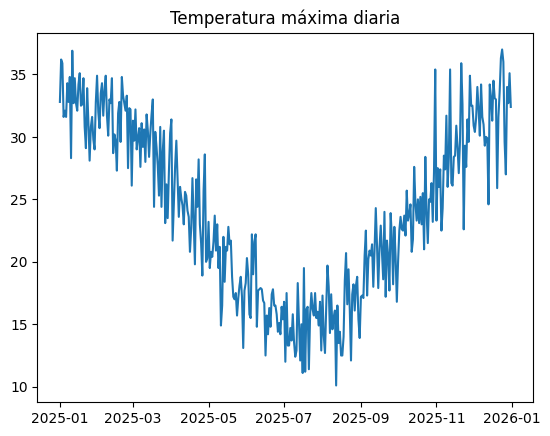

In [3]:
plt.plot(df['fecha'], df['temp_max'])
plt.title('Temperatura máxima diaria')
plt.show()

## 2. Estilo orientado a objetos (explícito) ✅
`fig` = el **lienzo** (Figure) · `ax` = el **área de dibujo** (Axes). Cada cambio se lo pedimos a `ax`.

Figure | Axes


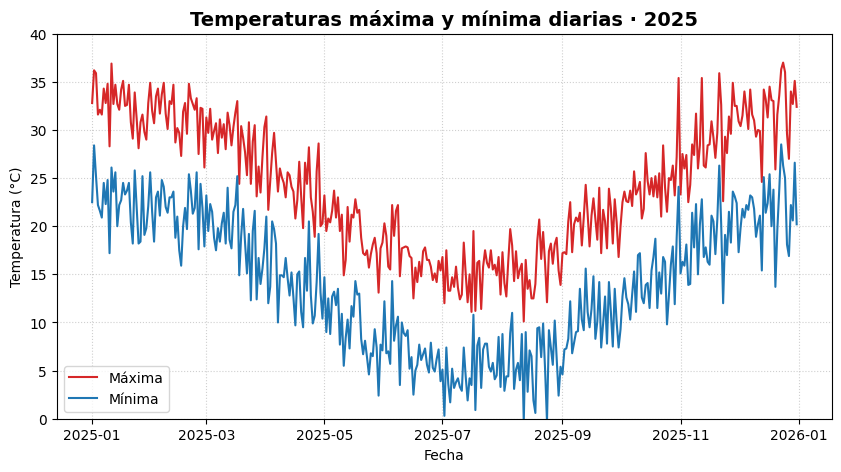

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
print(type(fig).__name__, '|', type(ax).__name__)

ax.plot(df['fecha'], df['temp_max'], label='Máxima', color='tab:red', linewidth=1.5)
ax.plot(df['fecha'], df['temp_min'], label='Mínima', color='tab:blue', linewidth=1.5)

ax.set_title('Temperaturas máxima y mínima diarias · 2025', fontsize=14, fontweight='bold')
ax.set_xlabel('Fecha')
ax.set_ylabel('Temperatura (°C)')
ax.set_ylim(0, 40)
ax.legend()
ax.grid(True, linestyle=':', alpha=0.6)
plt.show()

**Checklist de un gráfico legible:** ✔ título descriptivo · ✔ ejes con unidades · ✔ leyenda si hay más de una serie · ✔ grilla suave · ✔ `figsize` adecuado.

🗣️ *Pregunta:* ¿qué pasaría si quitamos `set_ylabel`? ¿Se entiende?

## 3. Subplots: dos Axes en una misma Figure
Una fila, dos columnas: **distribución** a la izquierda, **relación** a la derecha.

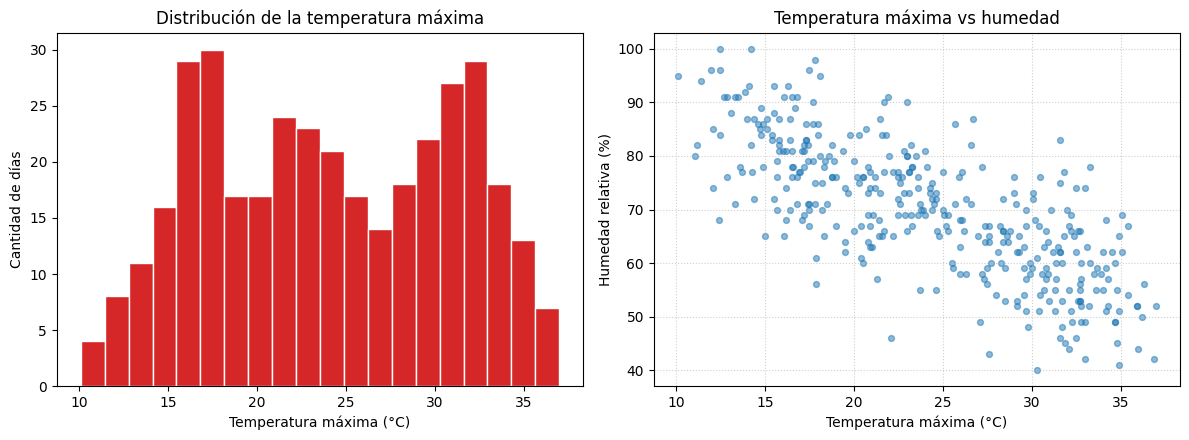

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4.5))   # axes es un array con 2 Axes

axes[0].hist(df['temp_max'], bins=20, color='tab:red', edgecolor='white')
axes[0].set_title('Distribución de la temperatura máxima')
axes[0].set_xlabel('Temperatura máxima (°C)')
axes[0].set_ylabel('Cantidad de días')

axes[1].scatter(df['temp_max'], df['humedad'], alpha=0.5, s=18, color='tab:blue')
axes[1].set_title('Temperatura máxima vs humedad')
axes[1].set_xlabel('Temperatura máxima (°C)')
axes[1].set_ylabel('Humedad relativa (%)')
axes[1].grid(True, linestyle=':', alpha=0.6)

fig.tight_layout()   # evita que los textos se solapen
plt.show()

## 4. Estilos predefinidos y guardado
Una línea cambia todo el aspecto: `plt.style.use(...)`.

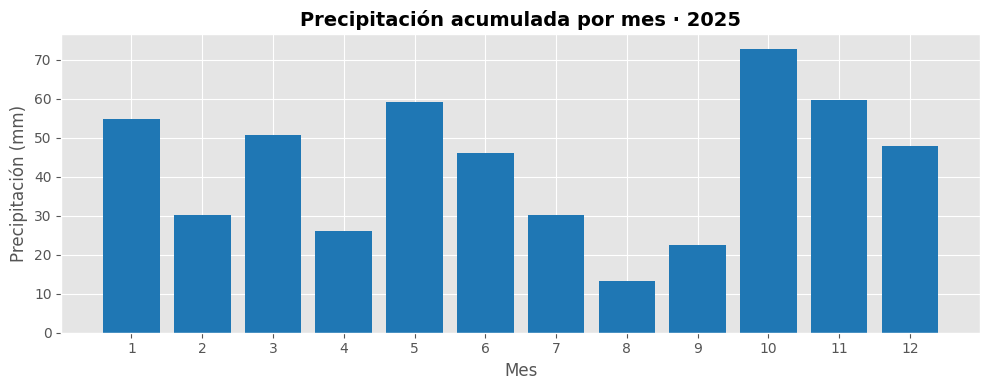

In [6]:
lluvia = df.groupby(df['fecha'].dt.month)['precipitacion_mm'].sum()

plt.style.use('ggplot')
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(lluvia.index, lluvia.values, color='tab:blue')
ax.set_title('Precipitación acumulada por mes · 2025', fontsize=14, fontweight='bold')
ax.set_xlabel('Mes')
ax.set_ylabel('Precipitación (mm)')
ax.set_xticks(range(1, 13))
fig.tight_layout()
fig.savefig('lluvia_mensual.png', dpi=150, bbox_inches='tight')
plt.show()
plt.style.use('default')

## 5. Síntesis
| Objeto | Qué es | Ejemplo |
|---|---|---|
| **Figure** | El lienzo que contiene todo | `fig` |
| **Axes** | Cada gráfico individual | `ax` / `axes[0]` |
| **Axis** | La regla graduada (ticks) | eje X o Y |

- Usá siempre `fig, ax = plt.subplots()`.
- Título + ejes con unidades + leyenda **no son opcionales**.
- `fig.tight_layout()` al final; `figsize` explícito.